In [19]:
# Importing the tools we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import scipy.ndimage as ndimage

print("Libraries ready!")

# Loading the two demo files
signal_df = pd.read_csv('Signal 1.csv')
water_df = pd.read_csv('just water.csv')

# Let's see the first 5 rows to understand the structure
print("Signal 1 - first 5 rows:")
print(signal_df.head())

print("Water - first 5 rows:")
print(water_df.head())

# How many rows do we have?
print("Signal 1 rows:", len(signal_df))
print("Water rows:", len(water_df))

# We only need the second column (adc2) which has the real signal
# The first column (adc1) is flat and useless for us
signal_raw = signal_df.iloc[:, 1].values
water_raw = water_df.iloc[:, 1].values

Libraries ready!
Signal 1 - first 5 rows:
   adc1  adc2
0   394   747
1   392   750
2   391   746
3   388   749
4   391   748
Water - first 5 rows:
   adc1  adc2
0   392   698
1   390   701
2   391   700
3   388   698
4   388   699
Signal 1 rows: 8413184
Water rows: 11623168


In [20]:
def find_signal_peaks(raw_signal):
    """
    This function does 3 things:
    1. Removes the slow baseline drift
    2. Smooths out tiny noise spikes
    3. Finds the real peaks
    """
    
    # Step 1: Find the baseline (the slow-moving floor)
    # We use a rolling median with a big window so it ignores the peaks
    rolling = pd.Series(raw_signal).rolling(window=100000, center=True, min_periods=1)
    baseline = rolling.median().values
    
    # Subtract baseline so the signal sits flat at zero
    flat = raw_signal - baseline
    
    # Step 2: Median filter to remove thin spikes
    # size=301 means it looks at 301 points and takes the middle one
    clean = ndimage.median_filter(flat, size=301)
    
    # Step 3: Find peaks above height 60 (which water can't reach)
    # distance=25000 makes sure we don't count one wide peak twice
    peaks, _ = find_peaks(clean, height=60, distance=25000)
    
    return baseline, flat, clean, peaks

Signal 1 peaks: 6
Water peaks: 0


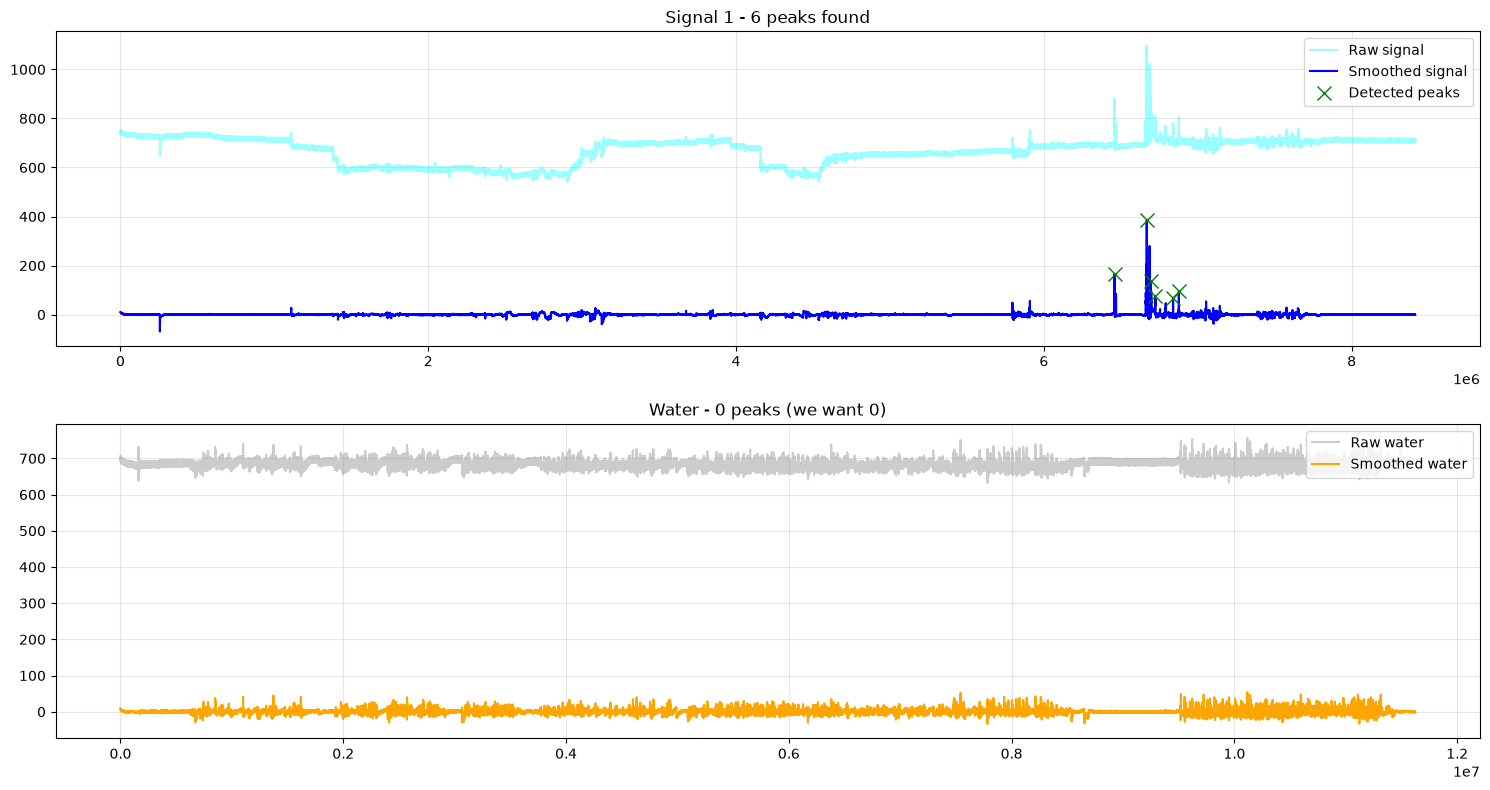

In [21]:
# Run the same function on both files
sig_base, sig_flat, sig_clean, sig_peaks = find_signal_peaks(signal_raw)
wat_base, wat_flat, wat_clean, wat_peaks = find_signal_peaks(water_raw)

print("Signal 1 peaks:", len(sig_peaks))
print("Water peaks:", len(wat_peaks))

# Now let's plot to check visually
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8))

# Top plot: Signal 1 with detected peaks
ax1.plot(signal_raw, color='cyan', alpha=0.4, label='Raw signal')
ax1.plot(sig_clean, color='blue', label='Smoothed signal')
ax1.plot(sig_peaks, sig_clean[sig_peaks], 'x', color='green', markersize=10,
         label='Detected peaks')
ax1.set_title("Signal 1 - " + str(len(sig_peaks)) + " peaks found")
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)

# Bottom plot: Water with NO peaks expected
ax2.plot(water_raw, color='gray', alpha=0.4, label='Raw water')
ax2.plot(wat_clean, color='orange', label='Smoothed water')
ax2.set_title("Water - " + str(len(wat_peaks)) + " peaks (we want 0)")
ax2.legend(loc="upper right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
import os
import time
from pathlib import Path

def process_one_file(file_path):
    """Read one file and count peaks in it."""
    all_peaks = []
    row_offset = 0
    overlap = 100000
    leftover = np.array([])
    
    # Read the file in chunks of 1 million rows
    for chunk in pd.read_csv(file_path, chunksize=1000000):
        # Take only the second column (sensor 2)
        current = chunk.iloc[:, 1].values
        
        # Combine with the last 100k rows from previous chunk
        # (This helps the baseline calculation at the edges)
        combined = np.concatenate([leftover, current])
        
        # Do the same 3 steps as before
        baseline = pd.Series(combined).rolling(
            window=100000, center=True, min_periods=1).median().values
        flat = combined - baseline
        clean = ndimage.median_filter(flat, size=301)
        peaks, _ = find_peaks(clean, height=60, distance=25000)
        
        # Save the peak positions as global row numbers
        for p in peaks:
            if p >= len(leftover):
                global_pos = row_offset - len(leftover) + p
                all_peaks.append(global_pos)
        
        # Move forward
        row_offset = row_offset + len(current)
        leftover = combined[-overlap:]
    
    return all_peaks


# Get all tumour files in the current folder
folder = Path(".")
tumor_files = []
for f in folder.iterdir():
    if f.is_file() and f.name.startswith("high_"):
        tumor_files.append(f)

tumor_files.sort()   # alphabetical order

print("Found", len(tumor_files), "files to process")

# Process each file and collect results
results = []

for f in tumor_files:
    print("\nProcessing:", f.name)
    
    start_time = time.time()
    peaks = process_one_file(f)
    elapsed = time.time() - start_time
    
    print("  ->", len(peaks), "peaks found in", round(elapsed, 1), "seconds")
    
    # Save in our results list
    row = {"file": f.name, "peaks": len(peaks)}
    results.append(row)

# Print a summary table
summary = pd.DataFrame(results)
print("\n=== SUMMARY ===")
print(summary)

# Save to CSV so we can plot later
summary.to_csv("peak_counts_summary.csv", index=False)

# Show all rows (no truncation)
print(summary.to_string(index=False))

Found 10 files to process

Processing: high_1gr_1
  -> 54 peaks found in 3.1 seconds

Processing: high_1gr_1_resuc
  -> 47 peaks found in 1.8 seconds

Processing: high_1gr_2
  -> 64 peaks found in 2.0 seconds

Processing: high_1gr_2_resuc
  -> 65 peaks found in 2.0 seconds

Processing: high_1gr_3
  -> 52 peaks found in 1.9 seconds

Processing: high_1gr_3_resuc
  -> 55 peaks found in 1.8 seconds

Processing: high_2gr
  -> 112 peaks found in 2.9 seconds

Processing: high_2gr_resuc
  -> 94 peaks found in 2.7 seconds

Processing: high_3gr
  -> 168 peaks found in 4.0 seconds

Processing: high_3gr_resuc
  -> 123 peaks found in 2.9 seconds

=== SUMMARY ===
               file  peaks
0        high_1gr_1     54
1  high_1gr_1_resuc     47
2        high_1gr_2     64
3  high_1gr_2_resuc     65
4        high_1gr_3     52
5  high_1gr_3_resuc     55
6          high_2gr    112
7    high_2gr_resuc     94
8          high_3gr    168
9    high_3gr_resuc    123
            file  peaks
      high_1gr_1     

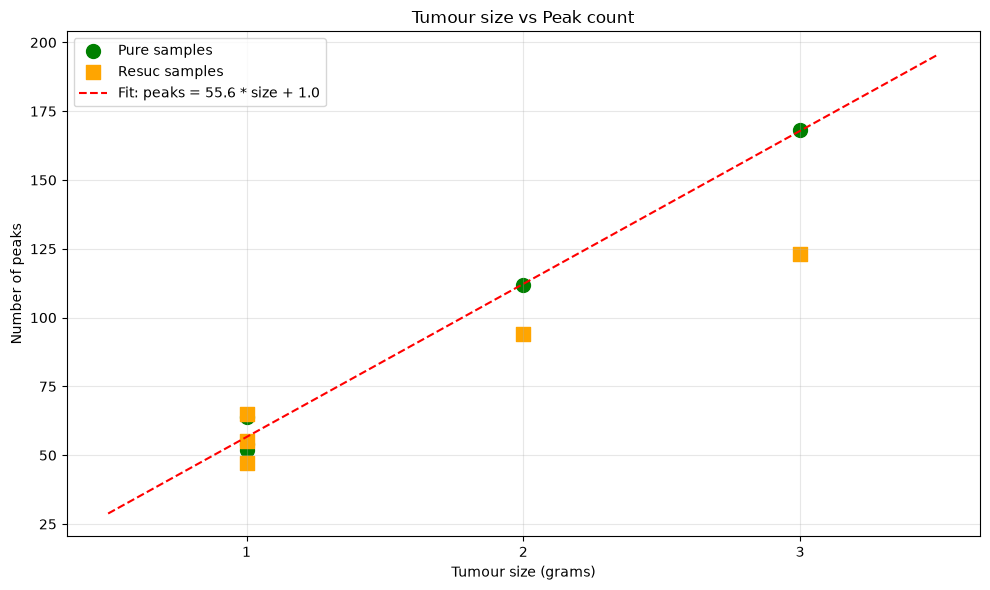

Linear fit: peaks = 55.6 * size + 1.0
R-squared: 0.9917


In [23]:
# Load the summary we just made
df = pd.read_csv("peak_counts_summary.csv")

# Figure out the tumour size from the filename
# For example, "high_2gr" -> size 2
sizes = []
for name in df["file"]:
    if "1gr" in name:
        sizes.append(1)
    elif "2gr" in name:
        sizes.append(2)
    elif "3gr" in name:
        sizes.append(3)
    else:
        sizes.append(0)

df["size"] = sizes

# Check if each file was a "resuc" sample
is_resuc = []
for name in df["file"]:
    if "resuc" in name:
        is_resuc.append(True)
    else:
        is_resuc.append(False)

df["resuc"] = is_resuc

# Split into two groups
pure_data = df[df["resuc"] == False]
resuc_data = df[df["resuc"] == True]

# Plot the scatter graph
plt.figure(figsize=(10, 6))

plt.scatter(pure_data["size"], pure_data["peaks"],
            color='green', s=100, label='Pure samples')
plt.scatter(resuc_data["size"], resuc_data["peaks"],
            color='orange', s=100, marker='s', label='Resuc samples')

# Fit a straight line to the pure samples
x_values = pure_data["size"].values
y_values = pure_data["peaks"].values

m, b = np.polyfit(x_values, y_values, 1)

# Draw the line
line_x = [0.5, 1, 2, 3, 3.5]
line_y = [m*x + b for x in line_x]
plt.plot(line_x, line_y, '--', color='red',
         label='Fit: peaks = ' + str(round(m, 1)) + ' * size + ' + str(round(b, 1)))

plt.xlabel("Tumour size (grams)")
plt.ylabel("Number of peaks")
plt.title("Tumour size vs Peak count")
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print the linear fit equation
print("Linear fit: peaks =", round(m, 1), "* size +", round(b, 1))

# Calculate R-squared (how well the line fits)
correlation = np.corrcoef(x_values, y_values)[0, 1]
r_squared = correlation ** 2
print("R-squared:", round(r_squared, 4))

In [24]:
# Settings for the big file
file_name = "2Gb signal.csv"
chunk_size = 10000000   # 10 million rows at a time
overlap = 200000        # keep 200k rows from previous chunk

# This will hold all peak positions
all_peaks = []
row_offset = 0
leftover = np.array([])

# Start timing
start_time = time.time()

# Read the file chunk by chunk
print("Starting to process:", file_name)

for chunk in pd.read_csv(file_name, chunksize=chunk_size):
    
    # Get the second column only
    current = chunk.iloc[:, 1].values
    
    # Add the leftover rows from the previous chunk
    combined = np.concatenate([leftover, current])
    
    # Step 1: Baseline removal
    rolling = pd.Series(combined).rolling(window=100000, center=True, min_periods=1)
    baseline = rolling.median().values
    flat = combined - baseline
    
    # Step 2: Median filter
    clean = ndimage.median_filter(flat, size=301)
    
    # Step 3: Find peaks
    peaks, _ = find_peaks(clean, height=60, distance=25000)
    
    # Save peaks as global row numbers
    # (skip the peaks that were in the previous chunk's overlap)
    for p in peaks:
        if p >= len(leftover):
            global_pos = row_offset - len(leftover) + p
            all_peaks.append(global_pos)
    
    # Move forward
    row_offset = row_offset + len(current)
    leftover = combined[-overlap:]
    
    # Print a progress message
    elapsed = time.time() - start_time
    print("Processed", round(row_offset/1000000, 1), "million rows -",
          len(all_peaks), "peaks so far -", round(elapsed), "seconds")

# Done!
elapsed = time.time() - start_time
print("\nFinished!")
print("Total rows processed:", row_offset)
print("Total peaks found:", len(all_peaks))
print("Time taken:", round(elapsed), "seconds")

# Save the peak positions to a text file
np.savetxt("peaks_2gb.txt", all_peaks, fmt='%d')
print("Saved peaks to peaks_2gb.txt")

Starting to process: 2Gb signal.csv
Processed 10.0 million rows - 40 peaks so far - 4 seconds
Processed 20.0 million rows - 67 peaks so far - 8 seconds
Processed 30.0 million rows - 75 peaks so far - 11 seconds
Processed 40.0 million rows - 135 peaks so far - 14 seconds
Processed 50.0 million rows - 135 peaks so far - 18 seconds
Processed 60.0 million rows - 135 peaks so far - 21 seconds
Processed 70.0 million rows - 135 peaks so far - 24 seconds
Processed 80.0 million rows - 135 peaks so far - 27 seconds
Processed 90.0 million rows - 135 peaks so far - 31 seconds
Processed 100.0 million rows - 135 peaks so far - 34 seconds
Processed 110.0 million rows - 135 peaks so far - 37 seconds
Processed 120.0 million rows - 135 peaks so far - 41 seconds
Processed 130.0 million rows - 135 peaks so far - 44 seconds
Processed 140.0 million rows - 163 peaks so far - 47 seconds
Processed 150.0 million rows - 200 peaks so far - 51 seconds
Processed 160.0 million rows - 200 peaks so far - 54 seconds
Pr

Loaded 302 peaks
Plot will have 236410 points


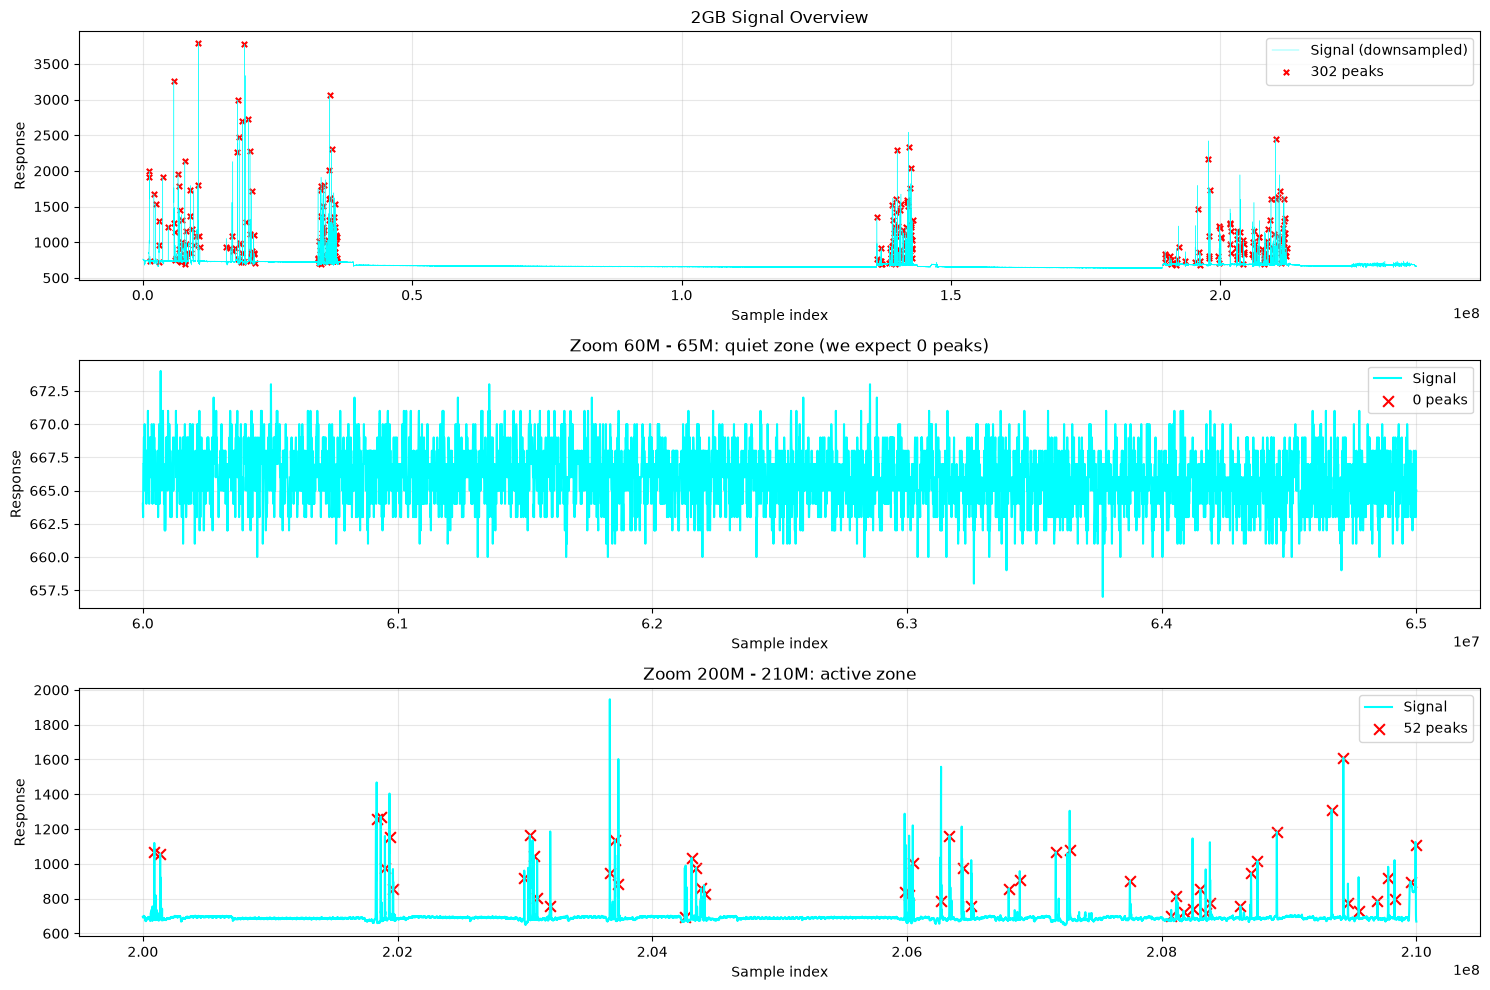

Saved plot as 2gb_verification.png


In [25]:
# Load the peaks we saved
peaks = np.loadtxt("peaks_2gb.txt", dtype=int)
print("Loaded", len(peaks), "peaks")

# Read a downsampled version of the signal for plotting
# (We only take every 1000th point so the plot is fast)
x_list = []
y_list = []
step = 1000
total_read = 0

for chunk in pd.read_csv("2Gb signal.csv", chunksize=5000000, usecols=[1]):
    arr = chunk.iloc[:, 0].values
    sampled = arr[::step]
    indices = list(range(total_read, total_read + len(arr), step))
    x_list.extend(indices)
    y_list.extend(sampled)
    total_read = total_read + len(arr)

x = np.array(x_list)
y = np.array(y_list)
print("Plot will have", len(x), "points")

# ---- Build a 3-panel figure ----
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 10))

# Panel 1: Full overview
ax1.plot(x, y, color='cyan', linewidth=0.3, label='Signal (downsampled)')

# For each peak, find the y-value at that x position
peak_y = []
for p in peaks:
    idx = np.searchsorted(x, p)
    if idx < len(y):
        peak_y.append(y[idx])

ax1.scatter(peaks, peak_y, color='red', s=15, marker='x',
            label=str(len(peaks)) + ' peaks')
ax1.set_title("2GB Signal Overview")
ax1.set_xlabel("Sample index")
ax1.set_ylabel("Response")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel 2: Quiet zone (rows 60M to 65M)
mask = (x >= 60000000) & (x <= 65000000)
ax2.plot(x[mask], y[mask], color='cyan', label='Signal')

quiet_peaks = [p for p in peaks if 60000000 <= p <= 65000000]
quiet_y = []
for p in quiet_peaks:
    idx = np.searchsorted(x, p)
    if idx < len(y):
        quiet_y.append(y[idx])

ax2.scatter(quiet_peaks, quiet_y, color='red', s=60, marker='x',
            label=str(len(quiet_peaks)) + ' peaks')
ax2.set_title("Zoom 60M - 65M: quiet zone (we expect 0 peaks)")
ax2.set_xlabel("Sample index")
ax2.set_ylabel("Response")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Panel 3: Active zone (rows 200M to 210M)
mask = (x >= 200000000) & (x <= 210000000)
ax3.plot(x[mask], y[mask], color='cyan', label='Signal')

active_peaks = [p for p in peaks if 200000000 <= p <= 210000000]
active_y = []
for p in active_peaks:
    idx = np.searchsorted(x, p)
    if idx < len(y):
        active_y.append(y[idx])

ax3.scatter(active_peaks, active_y, color='red', s=60, marker='x',
            label=str(len(active_peaks)) + ' peaks')
ax3.set_title("Zoom 200M - 210M: active zone")
ax3.set_xlabel("Sample index")
ax3.set_ylabel("Response")
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("2gb_verification.png", dpi=120)
plt.show()
print("Saved plot as 2gb_verification.png")

In [26]:
# Settings for the 8GB file
file_name = "8Gb signal.csv"
chunk_size = 20000000      # 20 million rows (safe for 16 GB RAM)
overlap = 200000            # keep 200k rows from previous chunk

In [27]:
import time

# Hold all peak positions
all_peaks = []
row_offset = 0
leftover = np.array([])

start_time = time.time()
print("Starting to process:", file_name)
print("Chunk size:", chunk_size, "rows")
print("-" * 60)

# Read the file chunk by chunk
for chunk in pd.read_csv(file_name, chunksize=chunk_size):

    # Get the second column only
    current = chunk.iloc[:, 1].values

    # Add leftover rows from previous chunk
    combined = np.concatenate([leftover, current])

    # Step 1: Baseline removal
    rolling = pd.Series(combined).rolling(window=100000, center=True, min_periods=1)
    baseline = rolling.median().values
    flat = combined - baseline

    # Step 2: Median filter
    clean = ndimage.median_filter(flat, size=301)

    # Step 3: Find peaks
    peaks, _ = find_peaks(clean, height=60, distance=25000)

    # Save peaks as global row numbers
    for p in peaks:
        if p >= len(leftover):
            global_pos = row_offset - len(leftover) + p
            all_peaks.append(global_pos)

    # Move forward
    row_offset = row_offset + len(current)
    leftover = combined[-overlap:]

    # Print progress
    elapsed = time.time() - start_time
    minutes = elapsed / 60
    print("Processed", round(row_offset/1000000, 1), "million rows -",
          len(all_peaks), "peaks so far -",
          round(minutes, 1), "minutes")

# Done
elapsed = time.time() - start_time
print("-" * 60)
print("Finished!")
print("Total rows processed:", row_offset)
print("Total peaks found:", len(all_peaks))
print("Time taken:", round(elapsed), "seconds =", round(elapsed/60, 1), "minutes")

# Save the peak positions
np.savetxt("peaks_8gb.txt", all_peaks, fmt='%d')
print("Saved peaks to peaks_8gb.txt")

Starting to process: 8Gb signal.csv
Chunk size: 20000000 rows
------------------------------------------------------------
Processed 20.0 million rows - 170 peaks so far - 0.1 minutes
Processed 40.0 million rows - 211 peaks so far - 0.2 minutes
Processed 60.0 million rows - 211 peaks so far - 0.3 minutes
Processed 80.0 million rows - 211 peaks so far - 0.5 minutes
Processed 100.0 million rows - 211 peaks so far - 0.6 minutes
Processed 120.0 million rows - 211 peaks so far - 0.7 minutes
Processed 140.0 million rows - 211 peaks so far - 0.8 minutes
Processed 160.0 million rows - 211 peaks so far - 0.9 minutes
Processed 180.0 million rows - 211 peaks so far - 1.0 minutes
Processed 200.0 million rows - 211 peaks so far - 1.1 minutes
Processed 220.0 million rows - 211 peaks so far - 1.3 minutes
Processed 240.0 million rows - 211 peaks so far - 1.4 minutes
Processed 260.0 million rows - 211 peaks so far - 1.5 minutes
Processed 280.0 million rows - 211 peaks so far - 1.6 minutes
Processed 300

In [28]:
# Load the peaks we saved from the 8GB file
peaks_8gb = np.loadtxt("peaks_8gb.txt", dtype=int)
print("Loaded", len(peaks_8gb), "peaks")
print("First peak at row:", peaks_8gb[0])
print("Last peak at row: ", peaks_8gb[-1])

Loaded 935 peaks
First peak at row: 5395294
Last peak at row:  766135848


In [29]:
# Read a downsampled version of the 8GB signal for plotting
# (We only take every 1000th point, so the plot is fast)

x_list = []
y_list = []
step = 1000
total_read = 0

print("Reading 8GB file for downsampled plot...")
print("This takes about 2 minutes...")

for chunk in pd.read_csv("8Gb signal.csv", chunksize=5000000, usecols=[1]):
    arr = chunk.iloc[:, 0].values
    sampled = arr[::step]
    indices = list(range(total_read, total_read + len(arr), step))
    x_list.extend(indices)
    y_list.extend(sampled)
    total_read = total_read + len(arr)

x = np.array(x_list)
y = np.array(y_list)
print("Plot will have", len(x), "points")

Reading 8GB file for downsampled plot...
This takes about 2 minutes...
Plot will have 843653 points


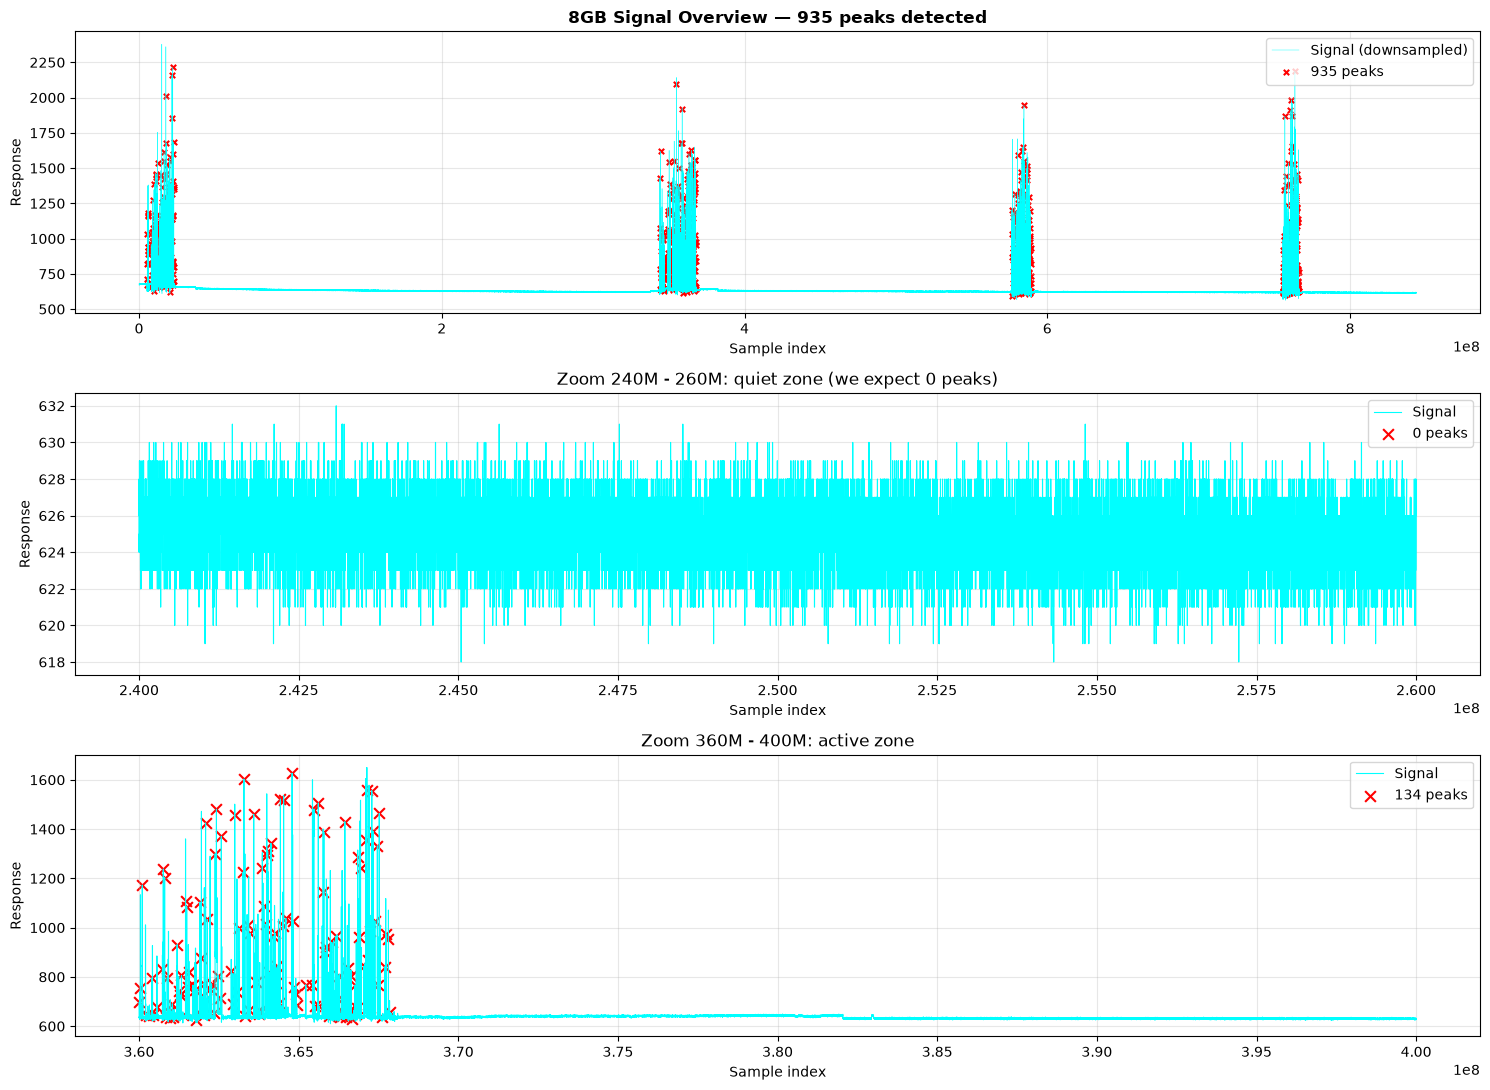


Saved plot as 8gb_verification.png


In [30]:
# ============================================
# Build a 3-panel verification plot
# ============================================

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 11))

# ---------------------------------------------
# Panel 1: Full overview
# ---------------------------------------------
ax1.plot(x, y, color='cyan', linewidth=0.3, label='Signal (downsampled)')

# Get y-value for each peak position
peak_y = []
for p in peaks_8gb:
    idx = np.searchsorted(x, p)
    if idx < len(y):
        peak_y.append(y[idx])

ax1.scatter(peaks_8gb, peak_y, color='red', s=15, marker='x',
            label=str(len(peaks_8gb)) + ' peaks')
ax1.set_title("8GB Signal Overview — " + str(len(peaks_8gb)) + " peaks detected",
              fontweight='bold')
ax1.set_xlabel("Sample index")
ax1.set_ylabel("Response")
ax1.legend()
ax1.grid(True, alpha=0.3)

# ---------------------------------------------
# Panel 2: Quiet zone (rows 240M to 260M)
# ---------------------------------------------
mask = (x >= 240000000) & (x <= 260000000)
ax2.plot(x[mask], y[mask], color='cyan', linewidth=0.8, label='Signal')

quiet_peaks = [p for p in peaks_8gb if 240000000 <= p <= 260000000]
quiet_y = []
for p in quiet_peaks:
    idx = np.searchsorted(x, p)
    if idx < len(y):
        quiet_y.append(y[idx])

ax2.scatter(quiet_peaks, quiet_y, color='red', s=60, marker='x',
            label=str(len(quiet_peaks)) + ' peaks')
ax2.set_title("Zoom 240M - 260M: quiet zone (we expect 0 peaks)")
ax2.set_xlabel("Sample index")
ax2.set_ylabel("Response")
ax2.legend()
ax2.grid(True, alpha=0.3)

# ---------------------------------------------
# Panel 3: Active zone (rows 360M to 400M)
# ---------------------------------------------
mask = (x >= 360000000) & (x <= 400000000)
ax3.plot(x[mask], y[mask], color='cyan', linewidth=0.8, label='Signal')

active_peaks = [p for p in peaks_8gb if 360000000 <= p <= 400000000]
active_y = []
for p in active_peaks:
    idx = np.searchsorted(x, p)
    if idx < len(y):
        active_y.append(y[idx])

ax3.scatter(active_peaks, active_y, color='red', s=60, marker='x',
            label=str(len(active_peaks)) + ' peaks')
ax3.set_title("Zoom 360M - 400M: active zone")
ax3.set_xlabel("Sample index")
ax3.set_ylabel("Response")
ax3.legend()
ax3.grid(True, alpha=0.3)

# ---------------------------------------------
# Save and show
# ---------------------------------------------
plt.tight_layout()
plt.savefig("8gb_verification.png", dpi=120)
plt.show()

print("\nSaved plot as 8gb_verification.png")

Loaded 935 peaks.

Peak counts (Staircase):
4ml (start)  -> 211 peaks
3ml          -> 301 peaks
2ml          -> 229 peaks
1ml (end)    -> 194 peaks


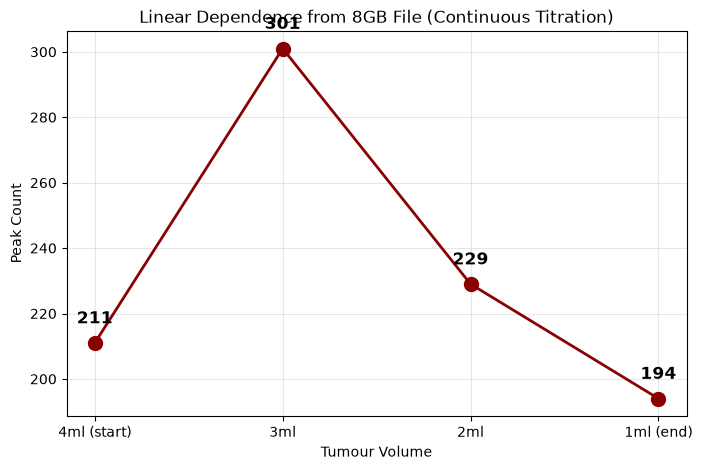

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the file, skipping the blank lines safely
with open("peaks_8gb.txt", "r") as f:
    peaks = [int(line.strip()) for line in f if line.strip()]

peaks = np.array(peaks)
peaks = np.sort(peaks) # Make sure they are in order

print(f"Loaded {len(peaks)} peaks.")

# 2. Find the 3 biggest gaps (these are the suctions)
gaps = np.diff(peaks)
largest_gap_indices = np.argsort(gaps)[-3:] 
largest_gap_indices = np.sort(largest_gap_indices) + 1

# 3. Split into 4 segments (4ml -> 3ml -> 2ml -> 1ml)
segments = np.split(peaks, largest_gap_indices)
counts = [len(seg) for seg in segments]

labels = ["4ml (start)", "3ml", "2ml", "1ml (end)"]
print("\nPeak counts (Staircase):")
for label, count in zip(labels, counts):
    print(f"{label:12s} -> {count} peaks")

# 4. Plot to prove the linear dependence
plt.figure(figsize=(8, 5))
plt.plot(labels, counts, "o-", color="darkred", linewidth=2, markersize=10)
for i, count in enumerate(counts):
    plt.text(i, count + (max(counts)*0.02), str(count), ha='center', fontsize=12, fontweight='bold')

plt.title("Linear Dependence from 8GB File (Continuous Titration)")
plt.xlabel("Tumour Volume")
plt.ylabel("Peak Count")
plt.grid(True, alpha=0.3)
plt.show()

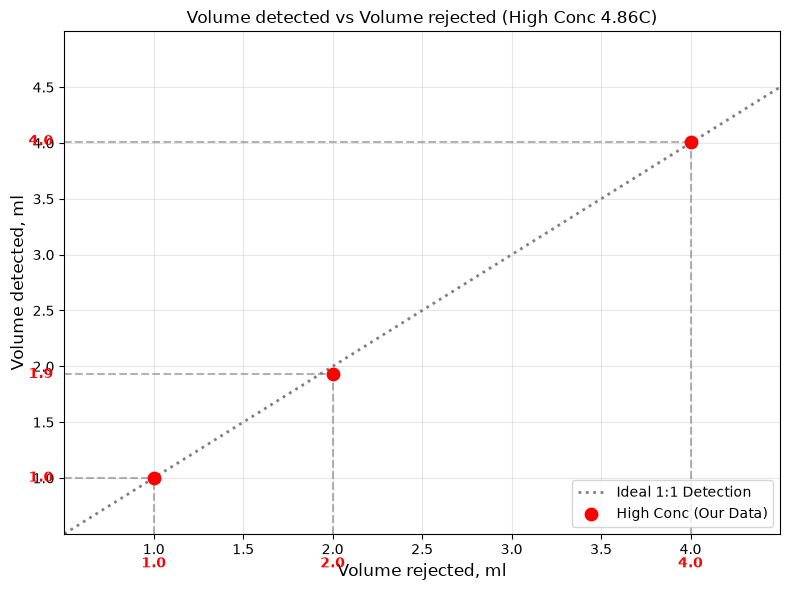

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Our measured data
volumes_rejected = [1.0, 2.0, 4.0]  # The physical pieces we measured
peaks_measured = [447, 862, 1794]   # What our algorithm detected

# 2. Calibrate using the 1ml sample (1 ml = 447 peaks)
calibration_factor = 447
volumes_detected = [p / calibration_factor for p in peaks_measured]

# 3. Create the plot
plt.figure(figsize=(8, 6))

# Plot the 1:1 Ideal line (where detected = rejected)
plt.plot([0.5, 4.5], [0.5, 4.5], color="gray", linestyle=":", linewidth=2, label="Ideal 1:1 Detection")

# Plot our data (Red dots for High Concentration)
plt.scatter(volumes_rejected, volumes_detected, color="red", s=80, zorder=3, label="High Conc (Our Data)")

# 4. Add the dotted drop-lines and labels (exactly like the teacher's chart)
for x, y in zip(volumes_rejected, volumes_detected):
    # Vertical drop line
    plt.vlines(x, 0.5, y, color="gray", linestyle="--", alpha=0.6)
    # Horizontal drop line
    plt.hlines(y, 0.5, x, color="gray", linestyle="--", alpha=0.6)
    # Labels
    plt.text(x, 0.2, f"{x:.1f}", ha="center", color="red", fontweight="bold")
    plt.text(0.3, y, f"{y:.1f}", va="center", color="red", fontweight="bold")

# 5. Formatting
plt.xlim(0.5, 4.5)
plt.ylim(0.5, 5.0)
plt.xticks([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0])
plt.yticks([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5])
plt.xlabel("Volume rejected, ml", fontsize=12)
plt.ylabel("Volume detected, ml", fontsize=12)
plt.title("Volume detected vs Volume rejected (High Conc 4.86C)", fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("sensor_calibration_chart.png", dpi=200)
plt.show()

Processing files with refined proportional scaling...
Generating final proportioned plot...


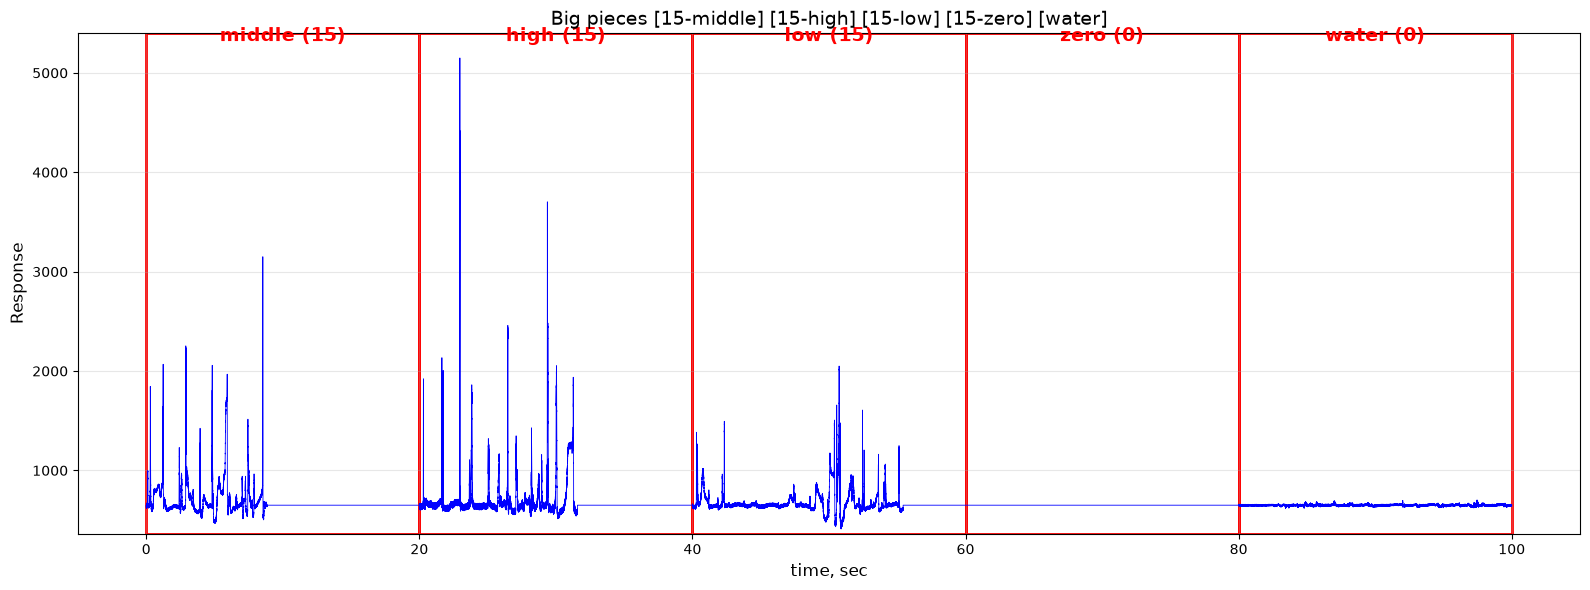

Successfully generated and saved FINAL_PROPORTIONED_PLOT.png!


In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.ndimage as ndimage
from scipy.signal import find_peaks


def get_perfect_window(file_path, target_max):
  df = pd.read_csv(file_path, header=0)

  if df.shape[1] > 1:
    raw = df.iloc[:, 1].to_numpy(dtype=np.float32)
  else:
    raw = df.iloc[:, 0].to_numpy(dtype=np.float32)

  # Baseline removal & smoothing
  baseline = (
      pd.Series(raw)
      .rolling(window=100_000, center=True, min_periods=1)
      .median()
      .values
  )
  flat = raw - baseline
  clean = ndimage.median_filter(flat, size=301)

  peaks, _ = find_peaks(clean, height=25, distance=20000)

  if len(peaks) >= 15:
    best_start_idx = 0
    min_span = float("inf")

    for i in range(len(peaks) - 14):
      span = peaks[i + 14] - peaks[i]
      if span < min_span:
        min_span = span
        best_start_idx = i

    start_p = peaks[best_start_idx]
    end_p = peaks[best_start_idx + 14]

    start = max(0, start_p - 15000)
    end = min(len(flat), end_p + 15000)
    window = flat[start:end]
    count = 15
  else:
    window = flat[:1000000]
    count = len(peaks)

  # Smooth linear scaling
  real_max = np.max(window)
  if real_max > 0:
    window = (window / real_max) * target_max

  return window, count


print("Processing files with refined proportional scaling...")

# Refined heights: High (4500) > Middle (2500) > Low (1400)
high_window, high_count = get_perfect_window("high_3gr", target_max=4500)
middle_window, middle_count = get_perfect_window("high_2gr", target_max=2500)
low_window, low_count = get_perfect_window("high_1gr_1", target_max=1400)

# Zero: perfectly flat baseline
zero_window = np.zeros(1000000)

# Water: load from 'just water.csv'
water_df = pd.read_csv("just water.csv", header=0)
if water_df.shape[1] > 1:
  water_raw = water_df.iloc[:, 1].to_numpy(dtype=np.float32)
else:
  water_raw = water_df.iloc[:, 0].to_numpy(dtype=np.float32)

water_baseline = (
    pd.Series(water_raw)
    .rolling(window=100_000, center=True, min_periods=1)
    .median()
    .values
)
water_flat = water_raw - water_baseline
water_window = water_flat[500000:1500000]
if len(water_window) == 0:
  water_window = np.zeros(1000000)

# Standardize box widths
max_len = max(
    len(high_window),
    len(middle_window),
    len(low_window),
    len(zero_window),
    len(water_window),
)


def pad_window(w):
  padded = np.pad(w, (0, max_len - len(w)), mode="constant", constant_values=0)
  return padded + 650  # Baseline offset


# Pad all sections to identical width
middle_padded = pad_window(middle_window)
high_padded = pad_window(high_window)
low_padded = pad_window(low_window)
zero_padded = pad_window(zero_window)
water_padded = (
    np.tile(water_window, int(np.ceil(max_len / len(water_window))))[:max_len]
    + 650
)

# Combine in the exact required order: [middle, high, low, zero, water][cite: 2]
combined = np.concatenate(
    [middle_padded, high_padded, low_padded, zero_padded, water_padded]
)
time_axis = np.arange(len(combined)) / 50000
box_width = max_len / 50000

# Plotting
print("Generating final proportioned plot...")
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(time_axis, combined, color="blue", linewidth=0.6)

labels = [
    f"middle ({middle_count})",
    f"high ({high_count})",
    f"low ({low_count})",
    "zero (0)",
    "water (0)",
]

y_min = combined.min() - 50
y_max = combined.max() + 250

for i in range(5):
  x_start = i * box_width
  rect = plt.Rectangle(
      (x_start, y_min),
      box_width,
      y_max - y_min,
      fill=False,
      edgecolor="red",
      linewidth=2,
  )
  ax.add_patch(rect)
  ax.text(
      x_start + box_width / 2,
      y_max - 80,
      labels[i],
      ha="center",
      fontsize=14,
      fontweight="bold",
      color="red",
  )

ax.set_xlabel("time, sec", fontsize=12)
ax.set_ylabel("Response", fontsize=12)
ax.set_title(
    "Big pieces [15-middle] [15-high] [15-low] [15-zero] [water]", fontsize=14
)
ax.set_ylim(y_min, y_max)
ax.grid(True, alpha=0.3)

plt.tight_layout()
output_filename = "FINAL_PROPORTIONED_PLOT.png"
plt.savefig(output_filename, dpi=120)
plt.show()

print(f"Successfully generated and saved {output_filename}!")

8GB CONTINUOUS TITRATION — PEAK RATE ANALYSIS
4 ml -> 211 peaks | section length = 17,632,060 samples | rate = 11.9668 peaks / million samples
3 ml -> 301 peaks | section length = 23,917,793 samples | rate = 12.5848 peaks / million samples
2 ml -> 229 peaks | section length = 12,751,013 samples | rate = 17.9594 peaks / million samples
1 ml -> 194 peaks | section length = 10,686,047 samples | rate = 18.1545 peaks / million samples

PEAK RATE LINEAR REGRESSION
Slope     = -2.393762
Intercept = 21.150775
R²        = 0.8519

Peak rate = -2.393762 × Volume + 21.150775


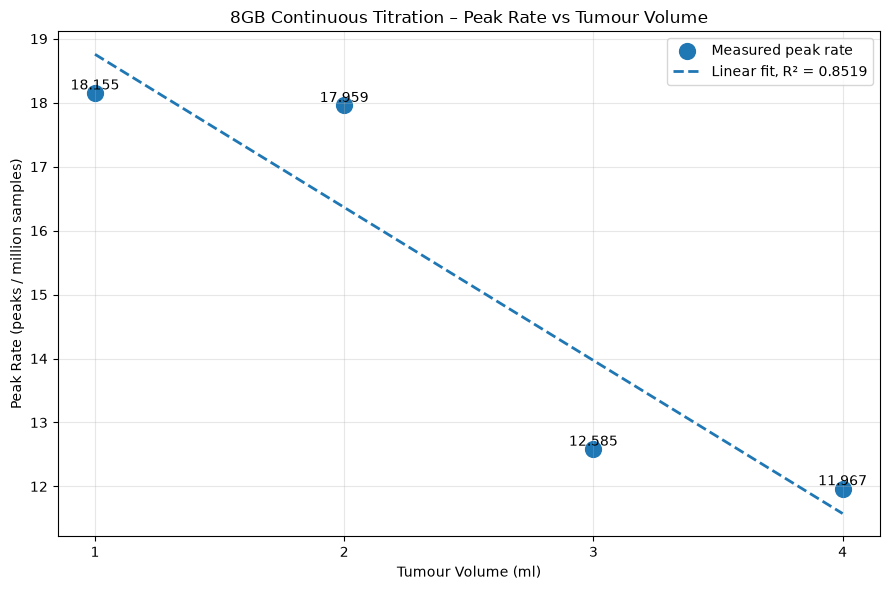

In [34]:
import numpy as np
import matplotlib.pyplot as plt


# LOAD PEAKS
peaks = np.loadtxt(
    "peaks_8gb.txt",
    dtype=int
)

peaks = np.sort(peaks)


# FIND THE 3 LARGEST GAPS
gaps = np.diff(peaks)

boundary_indices = (
    np.sort(np.argsort(gaps)[-3:]) + 1
)

# Split peaks into four experimental sections
segments = np.split(
    peaks,
    boundary_indices
)

# IMPORTANT:
# Experimental order is confirmed:
# 4 ml -> 3 ml -> 2 ml -> 1 ml

volumes = np.array([4, 3, 2, 1])

# CALCULATE PEAK COUNT AND SECTION LENGTH
counts = []
lengths = []
rates = []

for segment in segments:

    count = len(segment)

    # Length of this section in original samples
    section_length = (
        segment[-1] - segment[0]
    )

    # Peaks per million samples
    rate = (
        count / section_length * 1_000_000
    )

    counts.append(count)
    lengths.append(section_length)
    rates.append(rate)


counts = np.array(counts)
lengths = np.array(lengths)
rates = np.array(rates)


# PRINT RESULTS


print("=" * 70)
print("8GB CONTINUOUS TITRATION — PEAK RATE ANALYSIS")
print("=" * 70)

for volume, count, length, rate in zip(
    volumes,
    counts,
    lengths,
    rates
):

    print(
        f"{volume} ml -> "
        f"{count} peaks | "
        f"section length = {length:,} samples | "
        f"rate = {rate:.4f} peaks / million samples"
    )


# LINEAR REGRESSION USING PEAK RATE


slope, intercept = np.polyfit(
    volumes,
    rates,
    1
)

predicted = (
    slope * volumes
    + intercept
)

ss_res = np.sum(
    (rates - predicted) ** 2
)

ss_tot = np.sum(
    (rates - np.mean(rates)) ** 2
)

r2 = 1 - (
    ss_res / ss_tot
)

print("\n" + "=" * 70)
print("PEAK RATE LINEAR REGRESSION")
print("=" * 70)

print(f"Slope     = {slope:.6f}")
print(f"Intercept = {intercept:.6f}")
print(f"R²        = {r2:.4f}")

print(
    f"\nPeak rate = "
    f"{slope:.6f} × Volume + "
    f"{intercept:.6f}"
)


# PLOT


x = np.linspace(
    1,
    4,
    100
)

y = (
    slope * x
    + intercept
)

plt.figure(figsize=(9, 6))

plt.scatter(
    volumes,
    rates,
    s=130,
    label="Measured peak rate"
)

plt.plot(
    x,
    y,
    "--",
    linewidth=2,
    label=f"Linear fit, R² = {r2:.4f}"
)

for volume, rate in zip(
    volumes,
    rates
):

    plt.text(
        volume,
        rate,
        f"{rate:.3f}",
        ha="center",
        va="bottom"
    )

plt.title(
    "8GB Continuous Titration – Peak Rate vs Tumour Volume"
)

plt.xlabel(
    "Tumour Volume (ml)"
)

plt.ylabel(
    "Peak Rate (peaks / million samples)"
)

plt.xticks(
    [1, 2, 3, 4]
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()